# Khảo sát dữ liệu House Prices

In [2]:
from pathlib import Path
import sys

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
sys.path.insert(0, str(project))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.evaluation import DATA, RESULTS, SEED, load_data, make_folds, save_submission
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
figures = RESULTS / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Cấu trúc dữ liệu

In [3]:
print("Train:", train.shape, "| Test:", test.shape)
print("Dòng trùng:", train.duplicated().sum())
display(train.head())

Train: (1460, 81) | Test: (1459, 80)
Dòng trùng: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Nhận xét về cấu trúc dữ liệu

- Tập train có **1.460 dòng và 81 cột**. Tập test có **1.459 dòng và 80 cột**. Tập train có thêm cột `SalePrice`, là giá bán dùng làm biến mục tiêu. Mô hình sẽ dự đoán giá bán cho từng căn nhà trong tập test.
- Kết quả `train.duplicated().sum()` bằng **0**, tức là không có dòng nào trùng hoàn toàn khi xét tất cả các cột, kể cả `Id`.
- Năm dòng đầu cho thấy dữ liệu có cả biến số như `LotArea` và biến phân loại như `MSZoning`. Một số giá trị ở cột `Alley` hiển thị `NaN`. Ý nghĩa của các giá trị này sẽ được đối chiếu với `data_description.txt` ở phần khảo sát dữ liệu thiếu.

## 2. Phân phối giá

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

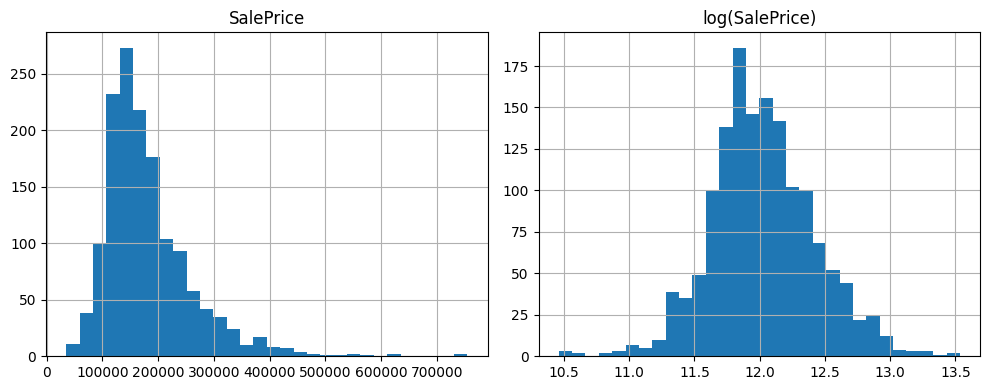

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train["SalePrice"].hist(ax=axes[0], bins=30)
np.log(train["SalePrice"]).hist(ax=axes[1], bins=30)
axes[0].set_title("SalePrice")
axes[1].set_title("log(SalePrice)")
fig.tight_layout()
fig.savefig(figures / "sale_price.png", dpi=160)
plt.show()


### Nhận xét về phân phối giá nhà

- Phân phối `SalePrice`: Giá nhà có xu hướng lệch phải rõ rệt. Phần lớn các căn nhà có giá tập trung trong khoảng 100.000 – 200.000 USD, trong khi một số căn có giá trên 400.000 USD, khiến phần đuôi phân phối kéo dài về bên phải.
- Giá trị ngoại lệ: Biểu đồ cho thấy một số căn nhà có giá rất cao, lên đến khoảng 750.000 USD. Đây là những giá trị có khả năng bất thường so với phần lớn dữ liệu và cần được xem xét trong quá trình phân tích.
- Phân phối `log(SalePrice)`: Sau khi áp dụng phép biến đổi logarit tự nhiên, phân phối trở nên cân đối hơn và có hình dạng gần với phân phối chuẩn. Phần lớn giá trị tập trung trong khoảng 11,5 – 12,5, cho thấy mức độ lệch phải đã giảm đáng kể.
- Ý nghĩa đối với mô hình: Phép biến đổi logarit giúp giảm ảnh hưởng của các giá trị giá nhà quá cao và ổn định hơn sự biến thiên của biến mục tiêu. Vì vậy, có thể sử dụng `log(SalePrice)` trong quá trình huấn luyện để hỗ trợ cải thiện khả năng dự đoán.
- Kết luận: Biến `SalePrice` có phân phối lệch phải, trong khi `log(SalePrice)` có phân phối cân đối hơn. Do đó, ưu tiên thử nghiệm biến mục tiêu `log(SalePrice)` khi xây dựng mô hình dự đoán giá nhà và đánh giá hiệu quả bằng kết quả thực nghiệm.


## 3. Dữ liệu thiếu

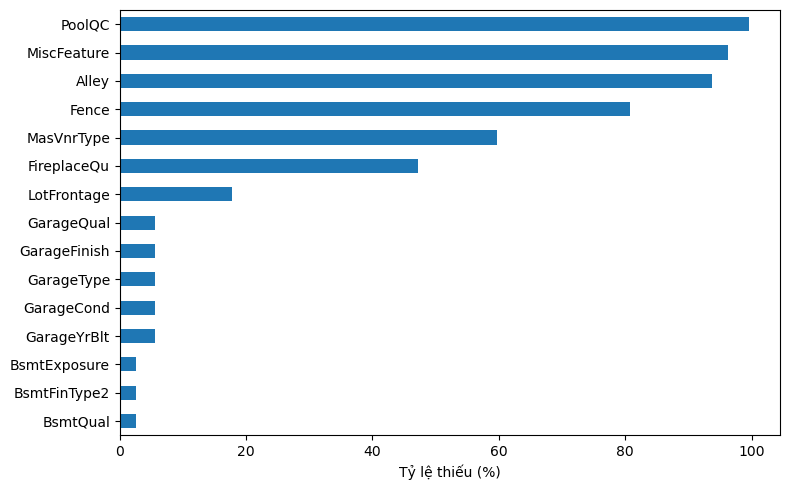

In [3]:
missing = train.isna().mean().mul(100).sort_values(ascending=False)
ax = missing[missing.gt(0)].head(15).sort_values().plot.barh(figsize=(8, 5))
ax.set_xlabel("Tỷ lệ thiếu (%)")
ax.figure.tight_layout()
ax.figure.savefig(figures / "missing_values.png", dpi=160)
plt.show()


### Nhận xét về dữ liệu thiếu

- Các thuộc tính `PoolQC`, `MiscFeature` và `Alley` có tỷ lệ thiếu rất cao, trên 90%. Tiếp theo là `Fence` và `MasVnrType`, với tỷ lệ thiếu lần lượt khoảng 80% và 60%.
- Một số giá trị thiếu không hẳn do lỗi dữ liệu mà có thể phản ánh đặc điểm của căn nhà. Ví dụ, giá trị thiếu ở `PoolQC` có thể cho biết căn nhà không có hồ bơi.
- Thuộc tính `LotFrontage` có tỷ lệ thiếu khoảng 18%, cần được xử lý vì đây là thông tin liên quan đến diện tích mặt tiền tiếp giáp đường.
- Các thuộc tính liên quan đến garage và basement có tỷ lệ thiếu thấp, nhưng vẫn cần xử lý trước khi huấn luyện mô hình.

**Kết luận:** Bộ dữ liệu có nhiều thuộc tính chứa giá trị thiếu với tỷ lệ khác nhau. Nhóm sẽ xử lý giá trị thiếu dựa trên loại dữ liệu và ý nghĩa của từng thuộc tính, nhằm hạn chế mất thông tin trước khi huấn luyện mô hình.